# Predicting MOT failure of cars in Great Britain

**Module:** 6COSC017C Machine Learning and Data Analytics · **CW1** · Notebook

**Question.** Before a car's annual MOT test, can facts a buyer or owner already knows predict whether it will **fail**?
- Those facts are age, mileage, make and model, fuel, engine size, region and the previous test's result.
- Fail means `F` or `PRS`: the car arrived with failure-level defects.

| section | contents |
|---|---|
| A | Data sources and loading (joins) |
| B | Exploratory data analysis |
| C | Data preparation |
| D | Modelling |
| E | Evaluation |

Reproduce: `uv sync`, then run all cells. Every file this notebook reads is in the repository; how they were built from DVSA's open data is in `data/SOURCE.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from motfail.data import make_label
from motfail.load import load_fuel_lookup, load_history, load_outcome_lookup, load_sample

SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")

## A. Data sources and loading

All data is published by the Driver and Vehicle Standards Agency (DVSA) as *Anonymised MOT tests and results*, under the Open Government Licence v3.0.

| source | file in this repo | key |
|---|---|---|
| 2025 test results (initial car tests, 1M sample) | `data/processed/mot_2025_sample.parquet` | `test_id`, `vehicle_id` |
| 2024 test results + 2024 test items (each car's previous test and its defects) | `data/processed/mot_2025_history.parquet` | `test_id` |
| DVSA lookup: fuel types | `data/lookup/dft_mdr_fuel_type_extract.csv` | `fuel_code` |
| DVSA lookup: test outcomes | `data/lookup/dft_mdr_test_outcome_extract.csv` | `result_code` |

### A.1 The 2025 sample

In [2]:
sample = load_sample()
print(f"{len(sample):,} rows × {sample.shape[1]} columns")
sample.sample(5, random_state=SEED)  # random rows: the source file is in mileage-sorted runs, so head() shows only zeros

1,000,000 rows × 14 columns


,test_id,vehicle_id,test_date,test_class_id,test_type,test_result,test_mileage,postcode_area,make,model,colour,fuel_type,cylinder_capacity,first_use_date
987231,1347023861,40492082,2025-12-15,4,NT,F,"57,854.000",CA,JAGUAR,XJ,BLUE,PE,"2,967.000",2004-03-31
79954,193861775,1303244295,2025-01-14,4,NT,P,"108,563.000",TF,FORD,TRANSIT,SILVER,DI,"2,198.000",2016-04-29
567130,1597582475,385043058,2025-07-04,4,NT,F,"130,798.000",IP,AUDI,A3,SILVER,PE,"1,595.000",2009-09-12
500891,620260615,1394232105,2025-06-09,4,NT,P,"29,868.000",SO,FORD,FIESTA TREND,GREY,PE,"1,084.000",2022-06-30
55399,196160821,1285318032,2025-01-21,4,NT,P,"75,056.000",RG,MAZDA,626,GREEN,PE,"1,991.000",2000-05-13


### A.2 Previous-test history

In [3]:
history = load_history()
print(f"{len(history):,} rows × {history.shape[1]} columns")
history.sample(5, random_state=SEED)

1,000,000 rows × 12 columns


,test_id,has_prev_test,prev_result,prev_fail,days_since_prev,miles_since_prev,mileage_rollback,prev_items_A,prev_items_F,prev_items_M,prev_items_P,prev_dangerous
987231,1347023861,0,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN
79954,193861775,1,P,0,365.000,"8,350.000",0,1.000,0.000,0.000,0.000,0.000
567130,1597582475,1,F,1,415.000,"6,564.000",0,4.000,2.000,2.000,0.000,1.000
500891,620260615,0,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN
55399,196160821,1,F,1,344.000,"9,216.000",0,0.000,1.000,0.000,0.000,0.000


### A.3 Join 1: sample ⨝ history on `test_id` (one-to-one)

In [4]:
assert sample["test_id"].is_unique, "duplicate test_id in sample"
assert history["test_id"].is_unique, "duplicate test_id in history"
assert sample["vehicle_id"].is_unique, "a vehicle appears twice"

df = sample.merge(history, on="test_id", how="left", validate="one_to_one", indicator=True)
print(f"sample {len(sample):,} | history {len(history):,} | joined {len(df):,}")
print(df["_merge"].value_counts().to_string())
df = df.drop(columns="_merge")

sample 1,000,000 | history 1,000,000 | joined 1,000,000
_merge
both          1000000
left_only           0
right_only          0


In [5]:
df["test_date"] = pd.to_datetime(df["test_date"])
df["first_use_date"] = pd.to_datetime(df["first_use_date"], errors="coerce")
df["vehicle_age_years"] = (df["test_date"] - df["first_use_date"]).dt.days / 365.25

no_prev = df["has_prev_test"] == 0
print(f"with a 2024 previous test: {(~no_prev).sum():,} ({(~no_prev).mean():.2%})")
print(f"without:                   {no_prev.sum():,} ({no_prev.mean():.2%})")
print("\nVehicle age (years) of tests without a previous test:")
print(df.loc[no_prev, "vehicle_age_years"].describe(percentiles=[.1, .25, .5, .75, .9]).to_string())
print(f"\nshare of them aged under 4 years: {(df.loc[no_prev, 'vehicle_age_years'] < 4).mean():.2%}")

with a 2024 previous test: 909,202 (90.92%)
without:                   90,798 (9.08%)

Vehicle age (years) of tests without a previous test:
count   90,798.000
mean         7.584
std          7.823
min         -0.003
10%          2.902
25%          2.960
50%          3.001
75%         10.951
90%         17.758
max        120.665

share of them aged under 4 years: 59.77%


**Join 1 result.** All 1,000,000 sample rows match exactly one history row (`validate="one_to_one"`, no `left_only` or `right_only` rows), so the join neither drops nor duplicates a test.

**Tests without a previous test: 90,798 (9.08%).** These are not failed matches: the history row exists, but the car had no initial test in 2024.
- **59.8%** of them are cars **under 4 years old** (median age 3.0). It is their first MOT, which is due at 3 years, so no earlier test exists.
- The rest are older cars whose previous test was before 2024, e.g. a car that was off the road for a while.

Their history features are missing *by design*. Section C keeps these rows and adds the `has_prev_test` flag, rather than dropping 9% of the data and every first-MOT car with them.

### A.4 Join 2: fuel codes ⨝ DVSA fuel lookup (many-to-one)

In [6]:
fuel = load_fuel_lookup()
assert fuel["fuel_code"].is_unique
print("raw fuel_type values in the sample:")
print(df["fuel_type"].value_counts(dropna=False).to_string())

raw fuel_type values in the sample:
fuel_type
PE                         532444
DI                         393170
HY                          40465
EL                          18857
HYBRID ELECTRIC (CLEAN)     10048
ED                           2650
ELECTRIC                     1777
GB                            224
OT                            184
LP                            168
CN                              4
FC                              4
GA                              4
GD                              1


In [7]:
before = len(df)
df = df.merge(fuel, left_on="fuel_type", right_on="fuel_code", how="left", validate="many_to_one")
assert len(df) == before
unmatched = df["fuel_name"].isna()
print(f"matched {(~unmatched).sum():,} | unmatched {unmatched.sum():,}")
print(df.loc[unmatched, "fuel_type"].value_counts(dropna=False).to_string())

matched 988,175 | unmatched 11,825
fuel_type
HYBRID ELECTRIC (CLEAN)    10048
ELECTRIC                    1777


**Join 2 result.** 988,175 rows (98.8%) match a DVSA fuel code. The 11,825 unmatched rows are not unknown fuels: the raw field sometimes holds the full name instead of the code.
- `HYBRID ELECTRIC (CLEAN)` (10,048 rows) is the lookup's name for `HY`.
- `ELECTRIC` (1,777 rows) is the lookup's name for `EL`.

Section C maps them back to their codes (error correction). The lookup also settles `ED`: it is *Electric Diesel*, a diesel hybrid.

### A.5 Join 3: outcomes ⨝ DVSA outcome lookup, and the target

In [8]:
outcome = load_outcome_lookup()
before = len(df)
df = df.merge(outcome, left_on="test_result", right_on="result_code", how="left", validate="many_to_one")
assert len(df) == before and df["result_name"].notna().all()
df["fail"] = make_label(df)
df.groupby(["test_result", "result_name"], observed=True).size().rename("tests").to_frame()

,,tests
test_result,result_name,
F,Failed,227881
P,Passed,719072
PRS,Pass with Rectification at Station,53047


**The target.**
- `fail = 1` for **F** (*Failed*) and **PRS** (*Pass with Rectification at Station*).
- `fail = 0` for **P** (*Passed*).

A PRS car *arrived* with failure-level defects that were repaired during the test. The buyer's question is about the car's state on arrival, so PRS counts as a fail. A sensitivity check with PRS counted as a pass is planned for Section E.

Retests and abandoned or aborted tests were excluded when the sample was built (`data/SOURCE.md`).

## B. Exploratory data analysis

### B.1 Structure and types

In [9]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 31 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   test_id            1000000 non-null  int64         
 1   vehicle_id         1000000 non-null  int64         
 2   test_date          1000000 non-null  datetime64[us]
 3   test_class_id      1000000 non-null  int64         
 4   test_type          1000000 non-null  category      
 5   test_result        1000000 non-null  str           
 6   test_mileage       1000000 non-null  float64       
 7   postcode_area      1000000 non-null  category      
 8   make               1000000 non-null  category      
 9   model              999999 non-null   category      
 10  colour             1000000 non-null  category      
 11  fuel_type          1000000 non-null  str           
 12  cylinder_capacity  979271 non-null   float64       
 13  first_use_date     1000000 non-null  da

31 columns, 194 MB in memory.
- Text fields with few distinct values are stored as `category` to save memory.
- The dates are real datetimes. `test_date` is only used to derive features (vehicle age, month), never as a raw model input.
- `test_id` and `vehicle_id` are identifiers, used for joins and the split, never as features.

### B.2 Numeric summary: centre, spread, shape

In [10]:
df["test_month"] = df["test_date"].dt.month
numeric = [
    "vehicle_age_years", "test_mileage", "cylinder_capacity",
    "days_since_prev", "miles_since_prev",
    "prev_items_F", "prev_items_P", "prev_items_A", "prev_items_M", "prev_dangerous",
]
summary = df[numeric].describe(percentiles=[.01, .25, .5, .75, .99]).T
summary["var"] = df[numeric].var()
summary["skew"] = df[numeric].skew()
summary["kurtosis"] = df[numeric].kurt()
summary["missing_%"] = df[numeric].isna().mean() * 100
summary

,count,mean,std,min,1%,25%,50%,75%,99%,max,var,skew,kurtosis,missing_%
vehicle_age_years,"1,000,000.000",10.701,5.621,-0.003,2.902,6.749,9.930,13.900,27.135,120.665,31.593,1.552,7.495,0.000
test_mileage,"1,000,000.000","75,275.823","45,753.231",0.000,"7,821.000","41,111.000","67,480.000","100,552.000","212,264.020","999,999.000","2,093,358,178.931",1.344,6.032,0.000
cylinder_capacity,"979,271.000","1,690.752",597.665,0.000,989.000,"1,329.000","1,590.000","1,991.000","3,950.000","55,000.000","357,203.796",3.841,142.528,2.073
days_since_prev,"909,202.000",363.011,39.127,2.000,183.000,357.000,364.000,371.000,480.000,727.000,"1,530.923",-1.691,20.746,9.080
miles_since_prev,"909,202.000","6,698.408","8,747.466","-873,599.000",59.000,"3,086.000","5,654.000","9,054.000","26,112.000","986,317.000","76,518,159.838",2.844,"1,722.146",9.080
prev_items_F,"909,202.000",0.498,1.256,0.000,0.000,0.000,0.000,0.000,6.000,33.000,1.579,3.626,18.192,9.080
prev_items_P,"909,202.000",0.080,0.363,0.000,0.000,0.000,0.000,0.000,2.000,13.000,0.132,5.794,44.647,9.080
prev_items_A,"909,202.000",1.302,1.860,0.000,0.000,0.000,0.000,2.000,8.000,36.000,3.461,2.149,7.350,9.080
prev_items_M,"909,202.000",0.144,0.459,0.000,0.000,0.000,0.000,0.000,2.000,10.000,0.211,4.094,22.224,9.080
prev_dangerous,"909,202.000",0.099,0.403,0.000,0.000,0.000,0.000,0.000,2.000,10.000,0.163,5.190,34.599,9.080


**Reading the table.**
- **Vehicle age:** median 9.9 years, mean 10.7, right-skewed (skew 1.55). Most cars are 7–14 years old, with a long tail of classics (maximum 120.7 years). The minimum, −0.003, is impossible: a first-use date after the test date.
- **Mileage:** median 67,480, mean 75,276 miles; skew 1.34. The maximum, 999,999, is a placeholder, not a reading.
- **Engine size:** median 1,590 cc. Kurtosis 142.5 means extreme outliers, up to 55,000 cc, which is not a real car engine.
- **Days since the previous test:** tightly centred on one year (median 364, middle half 357–371), the annual MOT cycle, with a short left tail (minimum 2 days).
- **Miles since the previous test:** median 5,654 a year. Kurtosis 1,722 comes from a few impossible jumps (−873,599 to +986,317), i.e. odometer errors.
- **Item counts at the previous test:** zero-inflated and right-skewed (all medians 0). Most cars had no failure items; a few had many (maximum 33).

**Why it matters for modelling.** Skew and outliers distort distance-based and linear models (KNN, logistic regression) far more than trees. Section C caps the impossible values and scales features for the models that need it.

### B.3 Missing values and impossible values

In [11]:
miss = pd.DataFrame({"missing": df.isna().sum(), "missing_%": df.isna().mean() * 100})
miss[miss["missing"] > 0].sort_values("missing", ascending=False)

,missing,missing_%
prev_fail,90798,9.080
prev_result,90798,9.080
days_since_prev,90798,9.080
miles_since_prev,90798,9.080
prev_items_A,90798,9.080
mileage_rollback,90798,9.080
prev_items_P,90798,9.080
prev_dangerous,90798,9.080
prev_items_F,90798,9.080
prev_items_M,90798,9.080


In [12]:
checks = {
    "test_mileage == 0": (df["test_mileage"] == 0).sum(),
    "test_mileage > 500,000": (df["test_mileage"] > 500_000).sum(),
    "cylinder_capacity == 0": (df["cylinder_capacity"] == 0).sum(),
    "cylinder_capacity > 8,000": (df["cylinder_capacity"] > 8_000).sum(),
    "first_use_date after test_date": (df["first_use_date"] > df["test_date"]).sum(),
    "vehicle age < 2.5 years": (df["vehicle_age_years"] < 2.5).sum(),
    "model == 'UNCLASSIFIED'": (df["model"] == "UNCLASSIFIED").sum(),
    "make == 'UNCLASSIFIED'": (df["make"] == "UNCLASSIFIED").sum(),
    "mileage went down since previous test": (df["mileage_rollback"] == 1).sum(),
    "|miles since previous| > 100,000": (df["miles_since_prev"].abs() > 100_000).sum(),
    "previous test < 30 days before": (df["days_since_prev"] < 30).sum(),
}
pd.Series(checks, name="rows").to_frame()

,rows
test_mileage == 0,1786
"test_mileage > 500,000",79
cylinder_capacity == 0,30
"cylinder_capacity > 8,000",34
first_use_date after test_date,1
vehicle age < 2.5 years,2457
model == 'UNCLASSIFIED',2065
make == 'UNCLASSIFIED',2
mileage went down since previous test,2684
"|miles since previous| > 100,000",939


In [13]:
# Are these values errors, or do they carry information?
zero = df["test_mileage"] == 0
print(f"fail rate, mileage recorded as 0: {df.loc[zero, 'fail'].mean():.2%}  (n = {zero.sum():,})")
print(f"fail rate, mileage > 0:           {df.loc[~zero, 'fail'].mean():.2%}")
print("\nmissing engine size by fuel code:")
print(pd.crosstab(df["fuel_type"], df["cylinder_capacity"].isna().rename("cc missing"))
        .query("`True` > 0").to_string())
print(f"\ncars older than 40 years: {(df['vehicle_age_years'] > 40).sum():,}; "
      f"oldest first use: {df['first_use_date'].min().date()}")

fail rate, mileage recorded as 0: 48.82%  (n = 1,786)
fail rate, mileage > 0:           28.06%

missing engine size by fuel code:
cc missing                False  True 
fuel_type                             
DI                       393031    139
EL                          173  18684
ELECTRIC                     15   1762
FC                            2      2
HYBRID ELECTRIC (CLEAN)   10012     36
LP                          166      2
OT                          183      1
PE                       532341    103

cars older than 40 years: 1,501; oldest first use: 1904-12-30


**Three different reasons for missing values.**
1. **History features (9.08%):** no previous test, mostly first-MOT cars (A.3). This is not random, so the absence is information: keep a `has_prev_test` flag and impute.
2. **Engine size (2.07%):** 20,446 of the 20,729 gaps are electric cars (`EL`, `ELECTRIC`), which have no cylinders. Structurally missing, not an error.
3. **Fuel name (1.18%):** the word-coded fuels from A.4, fixable exactly.

**Suspicious values** (counts in the table above):
- 1,786 zero mileages and 79 above 500,000 miles
- 30 zero and 34 above-8,000 cc engines
- 1 car first used after its test
- 2,065 `UNCLASSIFIED` models
- 939 impossible mileage changes between tests
- 374 tests less than 30 days after the previous one: in effect retests across the new year (`data/SOURCE.md`)

**Error or information?** Cars with mileage recorded as **0** fail **48.8%** of the time, against **28.1%** for the rest. So a zero is not a harmless gap; it probably marks an unreadable or broken odometer. Section C turns it into a flag instead of silently replacing it, so the model keeps the signal.

1,501 cars are **over 40 years old** (the oldest first used in 1904). Most cars over 40 are exempt from the MOT, so these are mostly voluntary tests of classics: a small, unusual group, not errors.

### B.4 Categorical features

In [14]:
categorical = ["make", "model", "colour", "postcode_area", "fuel_type"]
pd.DataFrame({
    "unique": [df[c].nunique() for c in categorical],
    "top": [df[c].value_counts().index[0] for c in categorical],
    "top_share_%": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in categorical],
    "values covering 90% of rows": [
        int((df[c].value_counts(normalize=True).cumsum() < 0.9).sum() + 1) for c in categorical
    ],
}, index=categorical)

,unique,top,top_share_%,values covering 90% of rows
make,779,FORD,13.263,21
model,8426,FIESTA,3.887,604
colour,20,BLACK,19.137,6
postcode_area,119,B,3.088,89
fuel_type,14,PE,53.244,2


**High cardinality.**
- 779 makes, but 21 cover 90% of tests.
- **8,426 models**, of which 604 are needed to cover 90%.
- 119 postcode areas.

One-hot encoding of `model` would create thousands of sparse columns. Section C groups rare values and uses frequency or target encoding fitted inside cross-validation.

`fuel_type` is dominated by two values: petrol 53.2%, then diesel.

### B.5 Target balance

              tests  share_%
test_result                 
P            719072   71.907
F            227881   22.788
PRS           53047    5.305

fail (F + PRS): 280,928 of 1,000,000 = 28.09%
majority-class baseline accuracy (always 'pass'): 71.91%


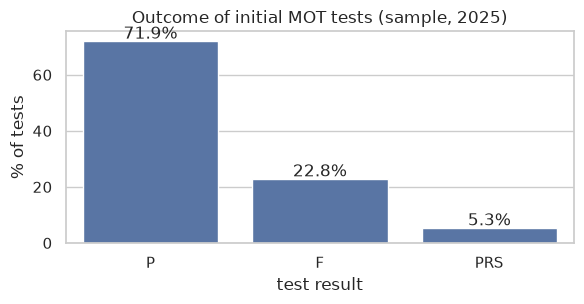

In [15]:
balance = df["test_result"].value_counts().rename("tests").to_frame()
balance["share_%"] = balance["tests"] / len(df) * 100
print(balance.to_string())
print(f"\nfail (F + PRS): {df['fail'].sum():,} of {len(df):,} = {df['fail'].mean():.2%}")
print(f"majority-class baseline accuracy (always 'pass'): {1 - df['fail'].mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
order = ["P", "F", "PRS"]
sns.barplot(x=order, y=[balance.loc[o, "share_%"] for o in order], ax=ax, color="#4c72b0")
ax.set(xlabel="test result", ylabel="% of tests", title="Outcome of initial MOT tests (sample, 2025)")
for i, o in enumerate(order):
    ax.text(i, balance.loc[o, "share_%"] + 1, f"{balance.loc[o, 'share_%']:.1f}%", ha="center")
plt.tight_layout(); plt.show()

**An imbalanced target.**
- 71.9% pass, 22.8% fail and 5.3% PRS, so **28.09% are fails**.
- A model that always predicts *pass* would score **71.9% accuracy** while catching no failing car. Accuracy is therefore not our main metric.

Section D uses precision, recall, F1 and PR-AUC; its random baseline is 0.281, the positive rate. It also stratifies every split, so each part keeps the 28% fail share.

### B.6 Fail rate by month

             tests  fail_rate
test_month                   
1            92680      0.287
2            84861      0.281
3           101471      0.272
4            74908      0.278
5            75489      0.272
6            80697      0.271
7            84066      0.283
8            78212      0.281
9            96967      0.276
10           94938      0.293
11           79262      0.292
12           56449      0.287


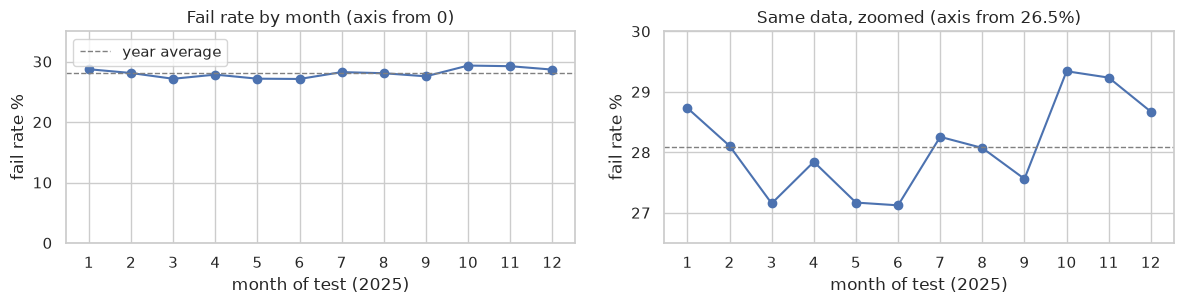

In [16]:
by_month = df.groupby("test_month")["fail"].agg(tests="size", fail_rate="mean")
print(by_month.to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, (ylim, title) in zip(axes, [((0, 35), "Fail rate by month (axis from 0)"),
                                    ((26.5, 30), "Same data, zoomed (axis from 26.5%)")]):
    ax.plot(by_month.index, by_month["fail_rate"] * 100, marker="o")
    ax.axhline(df["fail"].mean() * 100, ls="--", c="grey", lw=1, label="year average")
    ax.set(xlabel="month of test (2025)", ylabel="fail rate %", title=title, xticks=range(1, 13), ylim=ylim)
axes[0].legend(); plt.tight_layout(); plt.show()

**Seasonality is small but real.** The monthly fail rate moves between 27.1% (June) and 29.3% (October), a range of 2.2 percentage points. The left panel shows how small that is against the overall rate.
- **Higher from October to January.** Plausible but untested: winter wear on tyres, lights and wipers.
- **Part of the October–December rise is caused by how the sample was built** (one test per car, the earliest). Late in the year, cars that already had a 2025 test are excluded, and repeat tests mostly pass. Across *all* tests the October–December rates are 28.6%, 28.3% and 27.6% (`data/SOURCE.md`).

So `test_month` goes in as a feature, and the effect is described as *associated with* season, not caused by it.

### B.7 Distributions of the main numeric features, split by outcome

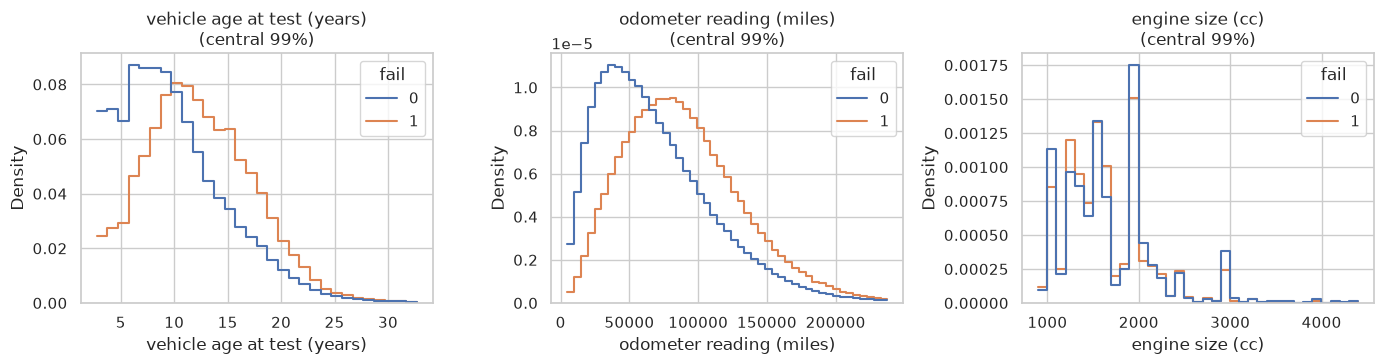

In [17]:
plot_cols = {
    "vehicle_age_years": "vehicle age at test (years)",
    "test_mileage": "odometer reading (miles)",
    "cylinder_capacity": "engine size (cc)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, label) in zip(axes, plot_cols.items()):
    lo, hi = df[col].quantile([0.005, 0.995])
    data = df[df[col].between(lo, hi)]
    binwidth = {"vehicle_age_years": 1, "test_mileage": 5_000, "cylinder_capacity": 100}[col]
    sns.histplot(data=data, x=col, hue="fail", stat="density", common_norm=False,
                 binwidth=binwidth, element="step", fill=False, ax=ax)
    ax.set(xlabel=label, title=f"{label}\n(central 99%)")
plt.tight_layout(); plt.show()

**What the distributions show.**
- **Age and mileage separate the classes.** The fail curves (1) sit clearly to the right: failing cars are older and have done more miles. These will be strong features, but they are correlated with each other (old cars have more miles). Section B.8 measures that.
- **Engine size barely separates them.** The spikes are standard engine sizes (1.0, 1.2, 1.4, 1.6 and 2.0 litres), not noise, and both classes share them.
- Age and mileage are right-skewed, so they are candidates for a log transform for the linear model (Section C).